## boeing Historical Airplane Orders & Deliveries dataset

In [66]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Download the Boeing dataset from kaggle

In [2]:
path = kagglehub.dataset_download("nurielreuven/boeing-historical-airplane-orders-deliveries")

print("Path to dataset files:", path)

100%|██████████| 69.5k/69.5k [00:00<00:00, 42.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/nurielreuven/boeing-historical-airplane-orders-deliveries/versions/1


In [81]:
df = pd.read_csv(path+"/OrdersandDeliveries.csv")

print(df.count())
new_names = {'Delivery Year ': 'Delivery Year'}
df = df.rename(columns=new_names)
print(df)

Country            9073
Customer Name      9073
Delivery Year      8048
Engine             9073
Model Series       9073
Order Month        9073
Order Year         9073
Region             9047
Delivery Total     9073
Order Total        9073
Unfilled Orders     338
dtype: int64
          Country           Customer Name Delivery Year Engine Model Series  \
0     Afghanistan  Ariana Afghan Airlines          1968     PW          727   
1     Afghanistan  Ariana Afghan Airlines          1970     PW          727   
2     Afghanistan  Ariana Afghan Airlines          1979     GE        DC-10   
3     Afghanistan  Ariana Afghan Airlines           NaN     CF      737-700   
4         Algeria             Air Algerie          1974     PW          727   
...           ...                     ...           ...    ...          ...   
9068     Zimbabwe            Air Zimbabwe          1987     PW      737-200   
9069     Zimbabwe            Air Zimbabwe          1990     PW    767-200ER   
9070     Zim

In [82]:
df = df[df['Order Year'] != 'All']
df = df[df['Delivery Year'] != 'All']
df = df.dropna(subset=['Delivery Year']).copy()
print(df)

          Country           Customer Name Delivery Year Engine Model Series  \
0     Afghanistan  Ariana Afghan Airlines          1968     PW          727   
1     Afghanistan  Ariana Afghan Airlines          1970     PW          727   
2     Afghanistan  Ariana Afghan Airlines          1979     GE        DC-10   
4         Algeria             Air Algerie          1974     PW          727   
5         Algeria             Air Algerie          1974     PW      737-200   
...           ...                     ...           ...    ...          ...   
9067       Zambia          Zambia Airways          1984     GE        DC-10   
9068     Zimbabwe            Air Zimbabwe          1987     PW      737-200   
9069     Zimbabwe            Air Zimbabwe          1990     PW    767-200ER   
9070     Zimbabwe            Air Zimbabwe          1989     PW    767-200ER   
9071     Zimbabwe            Air Zimbabwe          1986     PW      737-200   

     Order Month Order Year        Region Delivery 

Generate order/delivery dates columns

In [83]:
df['Order Year'] = pd.to_numeric(df['Order Year'])
df['Delivery Year'] = pd.to_numeric(df['Delivery Year'])
df['Order Total'] = pd.to_numeric(df['Order Total'].astype(str).str.replace(',',''))


In [84]:
month_map = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4,
             'May': 5, 'Jun': 6, 'Jul': 7, 'Aug': 8,
             'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
df['Order Month'] = df['Order Month'].map(month_map)
df['Order Month'].unique()

array([ 3,  4,  9,  1,  2,  5,  6,  7, 10, 11, 12,  8])

In [85]:
order_year_str_clean = df['Order Year'].astype(str).str.replace(r'\.0$', '', regex=True)
order_month_str_clean = df['Order Month'].astype(str).str.replace(r'\.0$', '', regex=True)
df['Order Date'] = pd.to_datetime(order_year_str_clean + '-' + order_month_str_clean + '-01')

delivery_year_str_clean = df['Delivery Year'].astype(str).str.replace(r'\.0$', '', regex=True)
df['Delivery Date'] = pd.to_datetime(delivery_year_str_clean + '-12-31')

df.head(10)

,Country,Customer Name,Delivery Year,Engine,Model Series,Order Month,Order Year,Region,Delivery Total,Order Total,Unfilled Orders,Order Date,Delivery Date
0,Afghanistan,Ariana Afghan Airlines,1968,PW,727,3,1968,Central Asia,1,1,NaN,1968-03-01,1968-12-31
1,Afghanistan,Ariana Afghan Airlines,1970,PW,727,4,1969,Central Asia,1,1,NaN,1969-04-01,1970-12-31
2,Afghanistan,Ariana Afghan Airlines,1979,GE,DC-10,9,1978,Central Asia,1,1,NaN,1978-09-01,1979-12-31
4,Algeria,Air Algerie,1974,PW,727,1,1974,Africa,1,1,NaN,1974-01-01,1974-12-31
5,Algeria,Air Algerie,1974,PW,737-200,1,1974,Africa,1,1,NaN,1974-01-01,1974-12-31
6,Algeria,Air Algerie,1975,PW,727,1,1974,Africa,1,1,NaN,1974-01-01,1975-12-31
7,Algeria,Air Algerie,1975,PW,737-200,1,1974,Africa,2,2,NaN,1974-01-01,1975-12-31
8,Algeria,Air Algerie,2015,CF,737-800,1,2014,Africa,2,2,NaN,2014-01-01,2015-12-31
9,Algeria,Air Algerie,2016,CF,737-800,1,2014,Africa,6,6,NaN,2014-01-01,2016-12-31
10,Algeria,Air Algerie,1971,PW,727,2,1970,Africa,2,2,NaN,1970-02-01,1971-12-31


Traverse each month and count number of orders yet to be fullfilled

In [86]:
months_range = pd.date_range(start=df['Order Date'].min(),
                           end=df['Delivery Date'].max(),
                           freq='MS')
print(months_range)
results = []
for current_month in months_range:
    mask = (df['Order Date'] <= current_month) & (df['Delivery Date'] > current_month)
    total_in_progress = df.loc[mask, 'Order Total'].sum()
    results.append({'Month': current_month, 'Planes_In_Progress': total_in_progress})

prog_df = pd.DataFrame(results)
print(prog_df.tail())
print(prog_df.head())

DatetimeIndex(['1955-10-01', '1955-11-01', '1955-12-01', '1956-01-01',
               '1956-02-01', '1956-03-01', '1956-04-01', '1956-05-01',
               '1956-06-01', '1956-07-01',
               ...
               '2022-03-01', '2022-04-01', '2022-05-01', '2022-06-01',
               '2022-07-01', '2022-08-01', '2022-09-01', '2022-10-01',
               '2022-11-01', '2022-12-01'],
              dtype='datetime64[ns]', length=807, freq='MS')
         Month  Planes_In_Progress
802 2022-08-01                 130
803 2022-09-01                 130
804 2022-10-01                 130
805 2022-11-01                 130
806 2022-12-01                 130
       Month  Planes_In_Progress
0 1955-10-01                  61
1 1955-11-01                 100
2 1955-12-01                 143
3 1956-01-01                 149
4 1956-02-01                 158


Plot the number of progressing planes by year

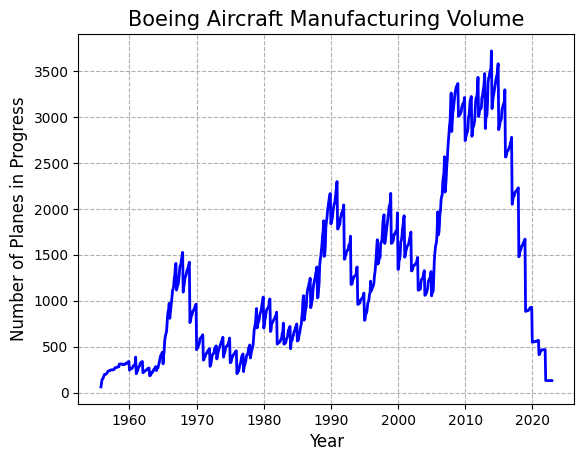

In [88]:
plt.plot(prog_df['Month'], prog_df['Planes_In_Progress'],
         color='blue', linewidth=2)

plt.title('Boeing Aircraft Manufacturing Volume', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Planes in Progress', fontsize=12)
plt.grid(True, linestyle='--')
plt.show()